# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
from aitlas.datasets import FieldDelineationFranceDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 1966


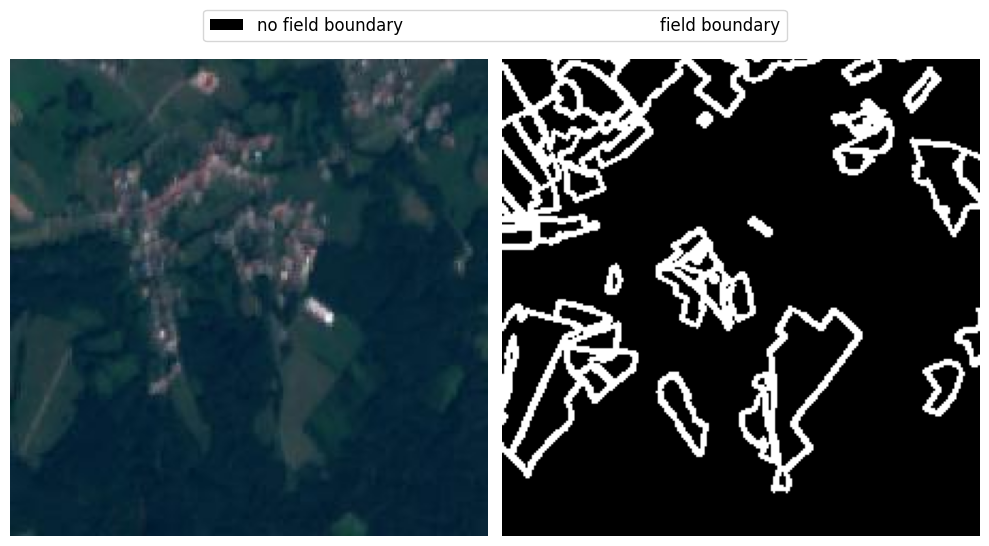

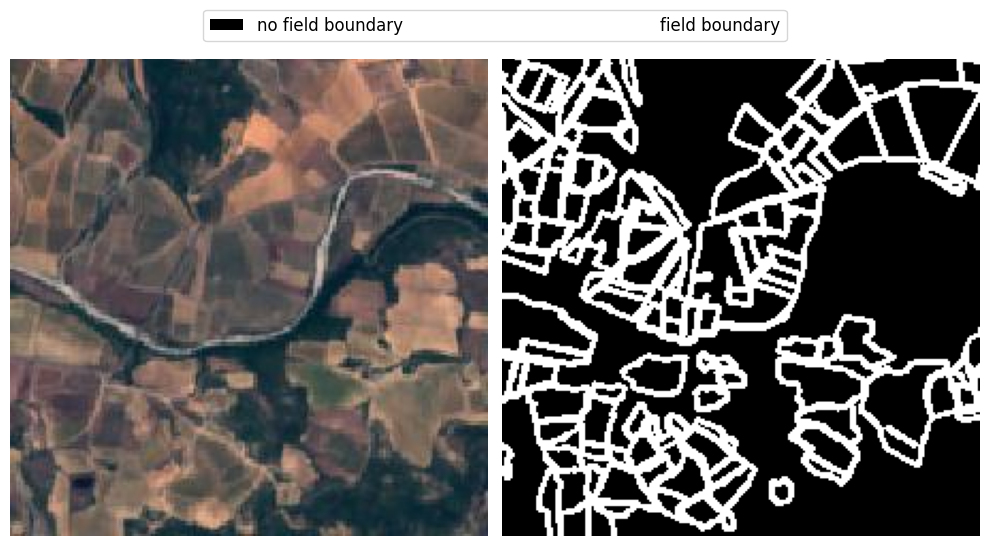

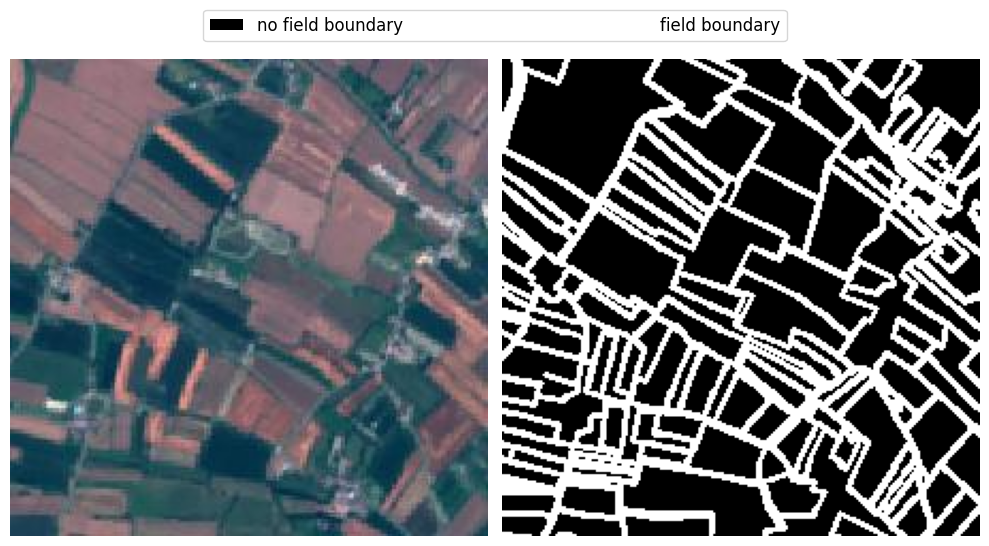

In [3]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/Field_delineation_france"
}
dataset = FieldDelineationFranceDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(3);
dataset.show_image(8);

In [13]:
dataset.data_distribution_table()

,Number of pixels
no field boundary,74902152.0
field boundary,23743864.0


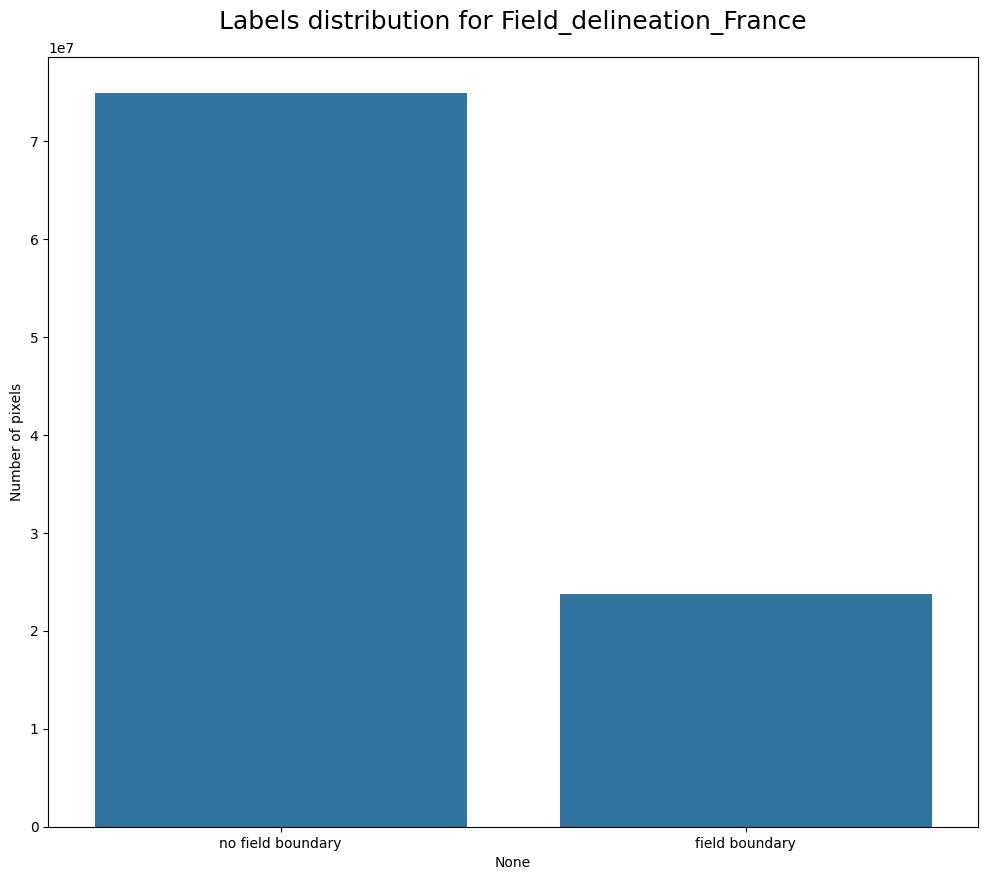

In [14]:
dataset.data_distribution_barchart();

## Load training data

In [3]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Field_delineation_france",
    "csv_file": "/home/dragik/data/FAIR_EO/Field_delineation_france/train.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = FieldDelineationFranceDataset(train_dataset_config)
len(train_dataset)

1574

## Create the model

In [4]:
epochs = 10
model_directory = "/home/dragik/data/FAIR_EO/Field_delineation_france"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [7]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-02-26 08:42:35,880 INFO Starting training.
training: 100%|██████████| 197/197 [00:54<00:00,  3.62it/s]
2025-02-26 08:43:30,309 INFO epoch: 1, time: 55, loss:  0.34374
testing on train set: 100%|██████████| 197/197 [00:54<00:00,  3.64it/s]
2025-02-26 08:44:26,524 INFO IOU:0.5638827962625018, IOU mean:0.47190935428119984, IOU per Class:[0.68056858 0.26325012]
training: 100%|██████████| 197/197 [00:54<00:00,  3.62it/s]
2025-02-26 08:45:21,013 INFO epoch: 2, time: 55, loss:  0.25940
testing on train set: 100%|██████████| 197/197 [00:54<00:00,  3.62it/s]
2025-02-26 08:46:15,465 INFO IOU:0.5829018234361286, IOU mean:0.48163639782792056, IOU per Class:[0.68547038 0.27780241]
training: 100%|██████████| 197/197 [00:54<00:00,  3.61it/s]
2025-02-26 08:47:09,996 INFO epoch: 3, time: 54, loss:  0.23276
testing on train set: 100%|██████████| 197/197 [00:54<00:00,  3.60it/s]
2025-02-26 08:48:04,812 INFO IOU:0.5897712257622693, IOU mean:0.49003130802645, IOU per Class:[0.68708625 0.29297637]
trai

## Evaluate the model

In [8]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/Field_delineation_france",
    "csv_file": "/home/dragik/data/FAIR_EO/Field_delineation_france/val.csv",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = FieldDelineationFranceDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "/home/dragik/data/FAIR_EO/Field_delineation_france/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

196


2025-02-26 09:01:42,569 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Field_delineation_france/checkpoint.pth.tar
2025-02-26 09:01:42,947 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Field_delineation_france/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 49/49 [00:07<00:00,  6.58it/s]


[{'IOU': 0.5873369804796988,
  'IOU mean': 0.4848891321010489,
  'IOU per Class': array([0.69752557, 0.27225269])}]

## Predictions

2025-03-10 09:38:25,680 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Field_delineation_france/checkpoint.pth.tar
2025-03-10 09:38:26,184 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Field_delineation_france/checkpoint.pth.tar at epoch 11


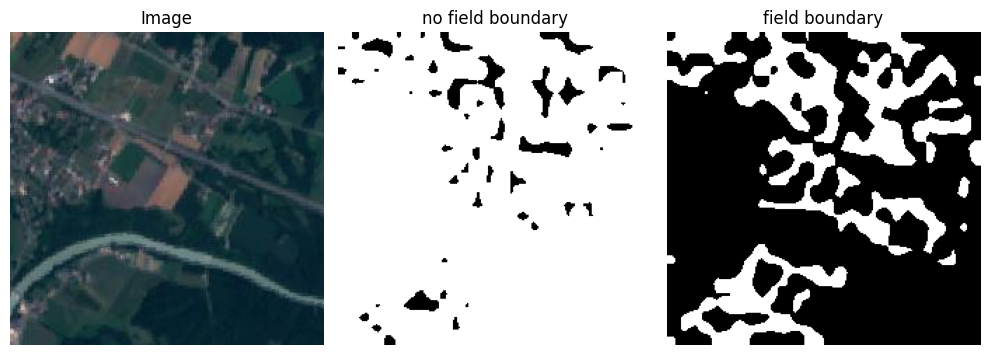

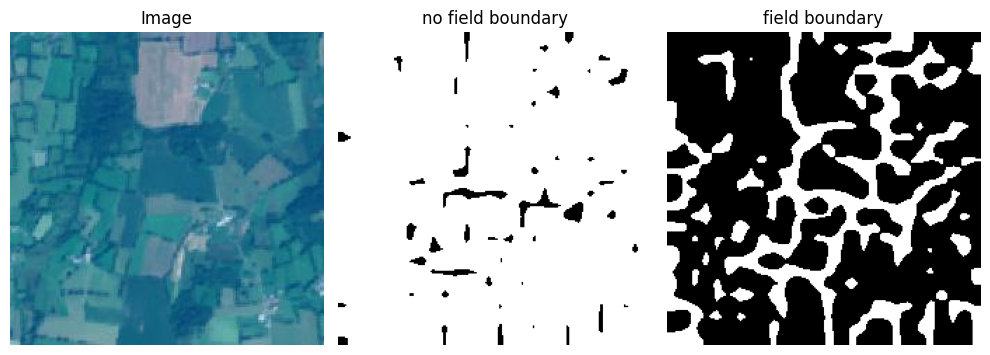

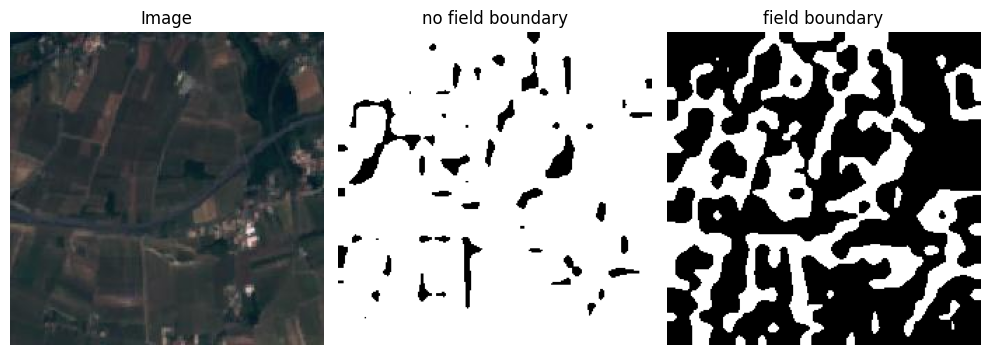

In [5]:
model_path = "/home/dragik/data/FAIR_EO/Field_delineation_france/checkpoint.pth.tar"
labels = ["no field boundary","field boundary"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
csv_file = "/home/dragik/data/FAIR_EO/Field_delineation_france/test.csv"

test_list = []
with open(csv_file, mode ='r')as file:
    csvFile = csv.reader(file)
    for lines in csvFile:
        test_list.append(lines[0])

image = image_loader('/home/dragik/data/FAIR_EO/Field_delineation_france/' + test_list[0])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/Field_delineation_france/' + test_list[15])
fig = model.predict_masks(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/Field_delineation_france/' + test_list[50])
fig = model.predict_masks(image, labels, transform)